# Box-Jenkins: การพยากรณ์ PM2.5 รายเดือนด้วย SARIMA

ข้อมูล PM2.5 เฉลี่ยรายเดือน ม.ค. 2024 – ต.ค. 2026 (34 เดือน)

| ส่วน | เนื้อหา |
|---|---|
| 0 | Setup และค่า Config |
| 1 | โหลดข้อมูล |
| 2 | สำรวจข้อมูล (กราฟ, Kruskal-Wallis) |
| 3 | Differencing → ADF → ACF/PACF |
| 4 | Train/Test split และ Grid search หา Optimized model |
| 5 | ตรวจสอบ Residual, ARCH-LM และความเสถียรของพารามิเตอร์ |
| 6 | พยากรณ์ 6 เดือนข้างหน้า |
| 7 | สรุปและข้อควรระวัง |

## 0. Setup

In [26]:
# ถ้ารันบน Colab ครั้งแรกและยังไม่มีแพ็กเกจ ให้เอา # ออกแล้วรันบรรทัดนี้
# !pip -q install pandas openpyxl matplotlib statsmodels scipy pmdarima

import sys, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal, jarque_bera, probplot, norm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

try:
    from pmdarima.arima.utils import nsdiffs          # ใช้ตรวจ Seasonal D (ไม่จำเป็นต้องมี)
except ImportError:
    nsdiffs = None

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

In [27]:
# ===================== Config (ปรับค่าได้ที่นี่ที่เดียว) =====================
DATA_PATH   = "/content/drive/MyDrive/Time Series/Project/PM2_5.xlsx"   # path บน Google Drive
SEASON      = 12          # คาบฤดูกาล (รายเดือน)
ALPHA       = 0.05        # ระดับนัยสำคัญ
N_TEST      = 6           # จำนวนเดือนที่กันไว้เป็น Test set
HORIZON     = 6           # จำนวนเดือนที่พยากรณ์ล่วงหน้า

# ขอบเขต Grid search (d และ D ตรึงตามผล ADF ในหัวข้อ 3)
D_ORDER, D_SEASONAL = 1, 1
MAX_P, MAX_Q, MAX_SP, MAX_SQ = 2, 2, 1, 1

# เกณฑ์คัดกรองโมเดลใน Grid search
MIN_EFFECTIVE_N = 12      # ต้องมีข้อมูลที่ใช้ประมาณค่าจริงอย่างน้อยเท่านี้
MIN_ROOT        = 1.001   # AR/MA root ต้องอยู่นอกวงกลมหนึ่งหน่วยอย่างน้อยเท่านี้
RMSE_TOL        = 0.01    # RMSE ต่างจากดีที่สุดไม่เกิน 1% ถือว่าเสมอกัน → เลือกโมเดลที่เรียบง่ายกว่า

MONTHS_TH = ["ม.ค.", "ก.พ.", "มี.ค.", "เม.ย.", "พ.ค.", "มิ.ย.", "ก.ค.", "ส.ค.", "ก.ย.", "ต.ค.", "พ.ย.", "ธ.ค."]
MONTHS_EN = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

In [28]:
# ===================== ฟังก์ชันที่ใช้ซ้ำทั้งโนตบุ๊ก =====================
def label(order, seasonal):
    return f"SARIMA{order}x{seasonal}"

def forecast_metrics(actual, pred):
    err = np.asarray(actual) - np.asarray(pred)
    mse = float(np.mean(err ** 2))
    return {"MAE": float(np.mean(np.abs(err))), "MSE": mse, "RMSE": float(np.sqrt(mse))}

def adf_report(series, name, maxlag=None):
    # ทดสอบ ADF (H0: มี unit root / ไม่ stationary) แล้วคืนผลเป็น dict
    x = series.dropna()
    if maxlag is None:      # Schwert rule แต่ไม่เกิน n//2 - 3 (กันไม่ให้ regression เหลือข้อมูลน้อยเกินไป; ตรงกับ Minitab)
        maxlag = min(int(np.ceil(12 * (len(x) / 100) ** 0.25)), len(x) // 2 - 3)
    stat, p, lags, nobs, crit, _ = adfuller(x, maxlag=maxlag, autolag="AIC")
    return {"Series": name, "N": nobs, "ADF stat": stat, "p-value": p, "Lags": lags,
            "Stationary?": "Yes" if p < ALPHA else "No"}

def fit_sarima(series, order, seasonal, enforce=True, maxiter=300):
    return SARIMAX(series, order=order, seasonal_order=seasonal,
                   enforce_stationarity=enforce, enforce_invertibility=enforce
                   ).fit(disp=False, maxiter=maxiter)

def screen(fit):
    # คืนเหตุผลที่ตัดโมเดลทิ้ง หรือ None ถ้าผ่านเกณฑ์
    if not fit.mle_retvals.get("converged", False):               return "Not converged"
    if fit.nobs_effective < MIN_EFFECTIVE_N:                      return f"Effective N < {MIN_EFFECTIVE_N}"
    if not (np.all(np.isfinite(fit.params)) and np.all(np.isfinite(fit.bse))): return "Invalid params/SE"
    if len(fit.arroots) and np.abs(fit.arroots).min() <= MIN_ROOT: return "AR root near boundary"
    if len(fit.maroots) and np.abs(fit.maroots).min() <= MIN_ROOT: return "MA root near boundary"
    return None

def residual_tests(fit, order, seasonal, lags=(6,)):
    # Ljung-Box + Jarque-Bera บน residual หลังช่วง burn-in
    resid = fit.resid.iloc[fit.loglikelihood_burn:].dropna()
    k = order[0] + order[2] + seasonal[0] + seasonal[2]            # จำนวนพารามิเตอร์ AR/MA
    out = {"resid": resid}
    try:
        out["ljung_box"] = acorr_ljungbox(resid, lags=list(lags), model_df=k, return_df=True)
    except Exception as e:
        out["ljung_box"] = f"คำนวณไม่ได้ ({str(e)[:60]})"
    out["jb_stat"], out["jb_p"] = jarque_bera(resid)[:2]
    return out

def residual_panel(resid, nlags=4):
    # กราฟ Residual 4 ช่อง: ลำดับเวลา / Histogram / Q-Q / ACF
    fig, ax = plt.subplots(2, 2, figsize=(12, 7))
    ax[0, 0].plot(resid.to_numpy(), marker="o"); ax[0, 0].axhline(0, color="red", ls="--"); ax[0, 0].set_title("Residuals")
    ax[0, 1].hist(resid, bins=6, density=True, alpha=.7)
    xs = np.linspace(resid.min(), resid.max(), 100)
    ax[0, 1].plot(xs, norm.pdf(xs, resid.mean(), resid.std()), "r"); ax[0, 1].set_title("Histogram")
    probplot(resid.to_numpy(), dist="norm", plot=ax[1, 0]); ax[1, 0].set_title("Normal Q-Q")
    plot_acf(resid.to_numpy(), lags=nlags, ax=ax[1, 1], zero=False); ax[1, 1].set_title("Residual ACF")
    plt.tight_layout(); plt.show()

## 1. โหลดข้อมูล

In [29]:
# ถ้าอยู่บน Colab จะ mount Google Drive ให้อัตโนมัติ
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

RAW = [50.57, 30.02, 22.08, 23.90, 24.71, 18.02, 18.03, 18.64, 28.04, 28.45, 32.60, 43.55,
       56.29, 47.42, 31.08, 19.39, 19.21, 19.17, 20.68, 18.24, 20.56, 22.20, 27.93, 35.53,
       44.85, 35.80, 26.07, 19.76, 18.01, 14.96, 17.97, 14.49, 16.42, 22.10]

try:
    df = pd.read_excel(DATA_PATH).dropna(how="all")
    print("โหลดจากไฟล์:", DATA_PATH)
except Exception:
    # ไม่พบไฟล์ → ใช้ข้อมูลชุดเดียวกันที่ฝังไว้ (ทำให้รันได้ทุกที่)
    df = pd.DataFrame({"ปี": [2024 + i // 12 for i in range(len(RAW))],
                       "เดือน": [MONTHS_TH[i % 12] for i in range(len(RAW))],
                       "PM2.5 เฉลี่ย (µg/m³)": RAW})
    print("ไม่พบไฟล์ — ใช้ข้อมูลที่ฝังไว้ในโนตบุ๊ก")

assert len(df) == 34, f"คาดว่ามี 34 เดือน แต่พบ {len(df)} แถว"
value_col = df.columns[2]

pm25 = pd.Series(pd.to_numeric(df[value_col], errors="coerce").to_numpy(),
                 index=pd.date_range("2024-01-01", periods=len(df), freq="MS"), name="PM2.5")
assert pm25.notna().all(), "พบข้อมูลสูญหาย"

print(f"n = {len(pm25)}  |  {pm25.index[0]:%b %Y} – {pm25.index[-1]:%b %Y}")
display(pm25.describe().round(2).to_frame().T)

ไม่พบไฟล์ — ใช้ข้อมูลที่ฝังไว้ในโนตบุ๊ก
n = 34  |  Jan 2024 – Oct 2026


,count,mean,std,min,25%,50%,75%,max
PM2.5,34.0,26.67,10.89,14.49,18.77,22.15,30.82,56.29


## 2. สำรวจข้อมูลเบื้องต้น

Kruskal-Wallis ทดสอบว่าค่า PM2.5 **แต่ละเดือนมีการกระจายต่างกัน** หรือไม่ (H₀: ทุกเดือนมีการกระจายเหมือนกัน) — ใช้เป็นหลักฐานว่ามี seasonality

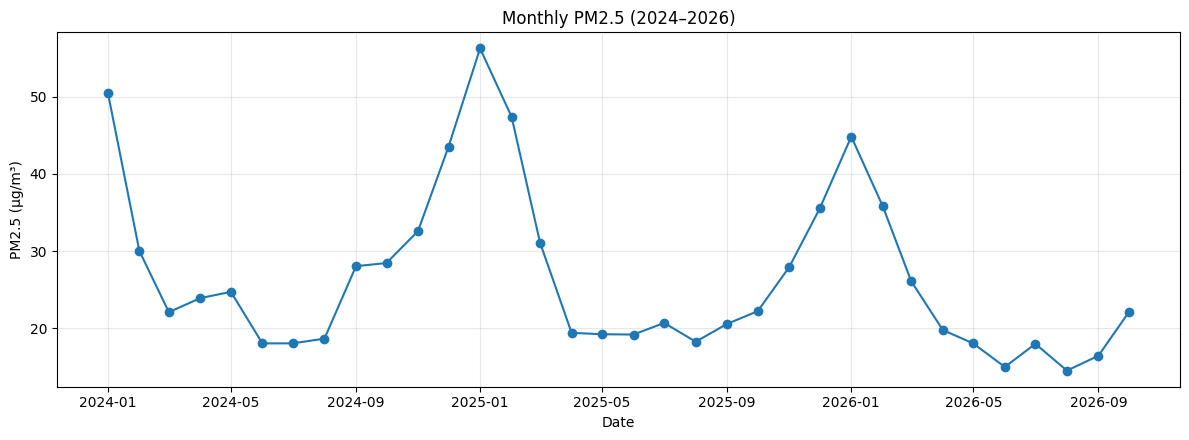

In [30]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(pm25.index, pm25, marker="o")
ax.set(title="Monthly PM2.5 (2024–2026)", xlabel="Date", ylabel="PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

จำนวนข้อมูลต่อเดือน: {'ม.ค.': 3, 'ก.พ.': 3, 'มี.ค.': 3, 'เม.ย.': 3, 'พ.ค.': 3, 'มิ.ย.': 3, 'ก.ค.': 3, 'ส.ค.': 3, 'ก.ย.': 3, 'ต.ค.': 3, 'พ.ย.': 2, 'ธ.ค.': 2}

Kruskal-Wallis H = 26.9445, p-value = 0.004685 → ปฏิเสธ H0 (แต่ละเดือนต่างกัน = มี seasonality)


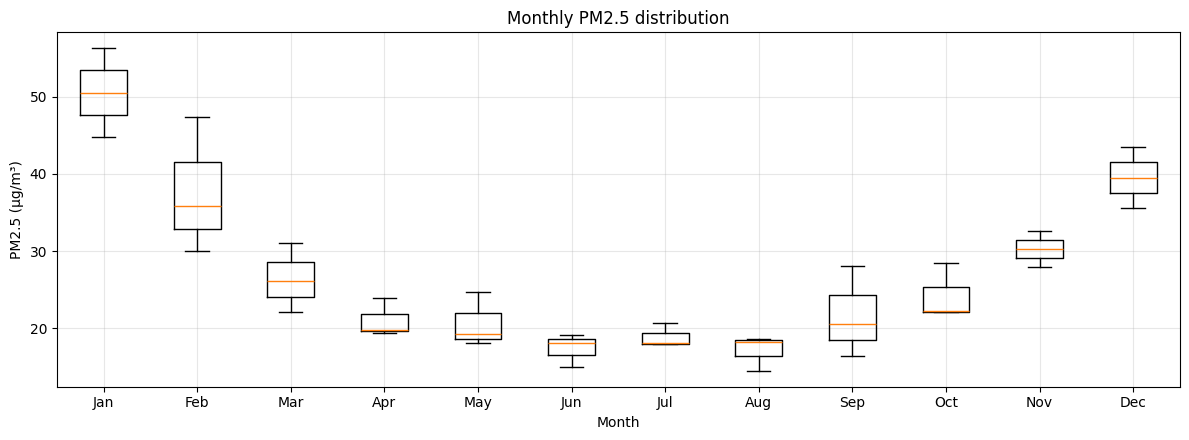

In [31]:
groups = [df.loc[df["เดือน"].astype(str).str.strip() == m, value_col].astype(float).dropna().values
          for m in MONTHS_TH]
print("จำนวนข้อมูลต่อเดือน:", dict(zip(MONTHS_TH, map(len, groups))))

H, p_kw = kruskal(*groups)
print(f"\nKruskal-Wallis H = {H:.4f}, p-value = {p_kw:.6f} →",
      "ปฏิเสธ H0 (แต่ละเดือนต่างกัน = มี seasonality)" if p_kw < ALPHA else "ไม่ปฏิเสธ H0")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.boxplot(groups, tick_labels=MONTHS_EN)
ax.set(title="Monthly PM2.5 distribution", xlabel="Month", ylabel="PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

## 3. Differencing → ADF → ACF/PACF

ลำดับ: **สร้างอนุกรมที่ difference แล้วก่อน → ทดสอบ ADF** (H₀: ไม่ stationary)

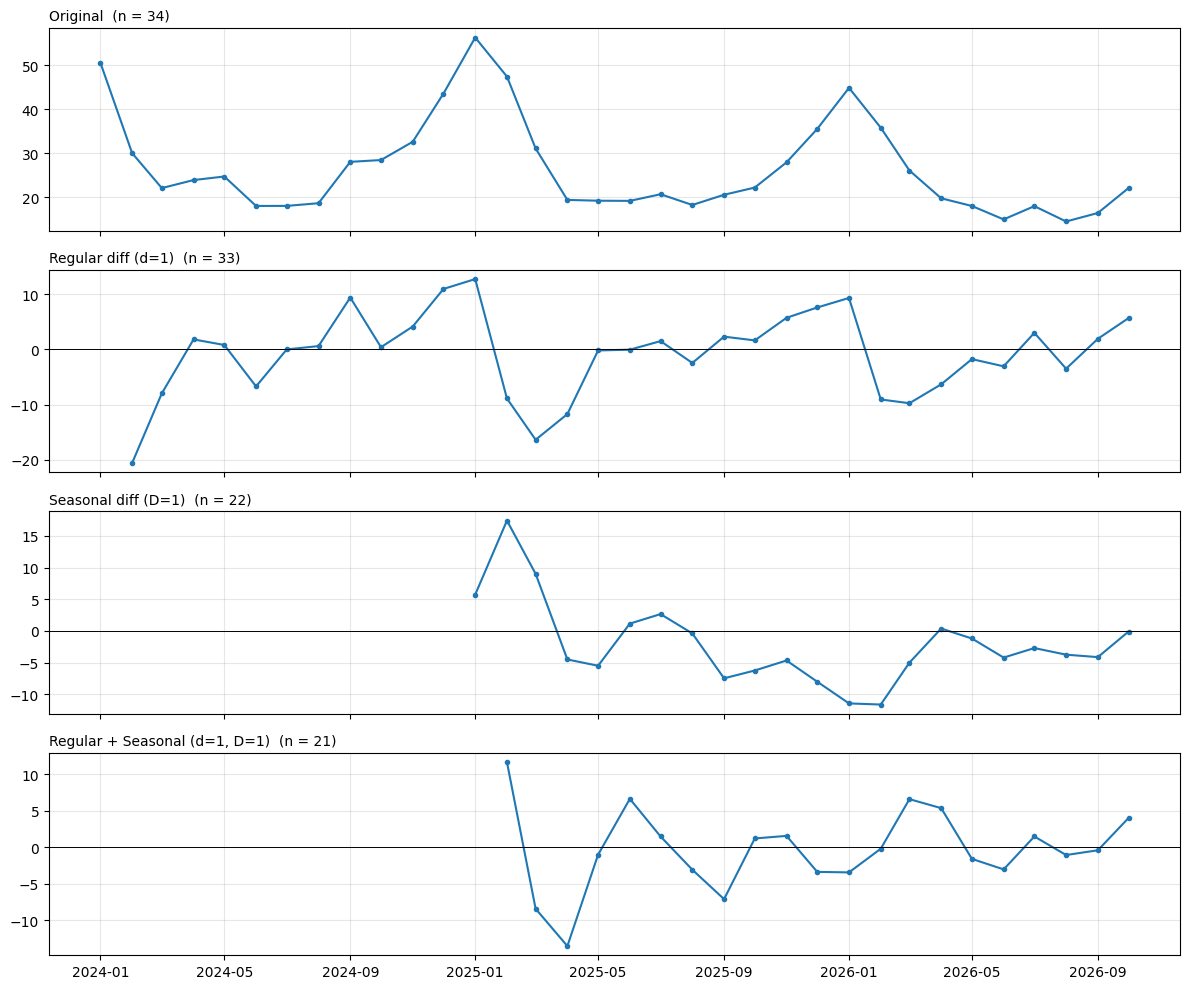

,N,ADF stat,p-value,Lags,Stationary?
Series,,,,,
Original,23,-0.0941,0.9500,10,No
Regular diff (d=1),23,-4.3058,0.0004,9,Yes
Seasonal diff (D=1),19,-2.0085,0.2829,2,No
"Regular + Seasonal (d=1, D=1)",19,-7.3333,0.0000,1,Yes


In [32]:
series_set = {
    "Original":                       pm25,
    "Regular diff (d=1)":             pm25.diff().dropna(),
    "Seasonal diff (D=1)":            pm25.diff(SEASON).dropna(),
    "Regular + Seasonal (d=1, D=1)":  pm25.diff().diff(SEASON).dropna(),
}

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (name, s) in zip(axes, series_set.items()):
    ax.plot(s, marker="o", ms=3); ax.set_title(f"{name}  (n = {len(s)})", loc="left", fontsize=10)
    if name != "Original": ax.axhline(0, color="k", lw=.7)
plt.tight_layout(); plt.show()

adf_table = pd.DataFrame([adf_report(s, n) for n, s in series_set.items()]).set_index("Series")
display(adf_table.round(4))

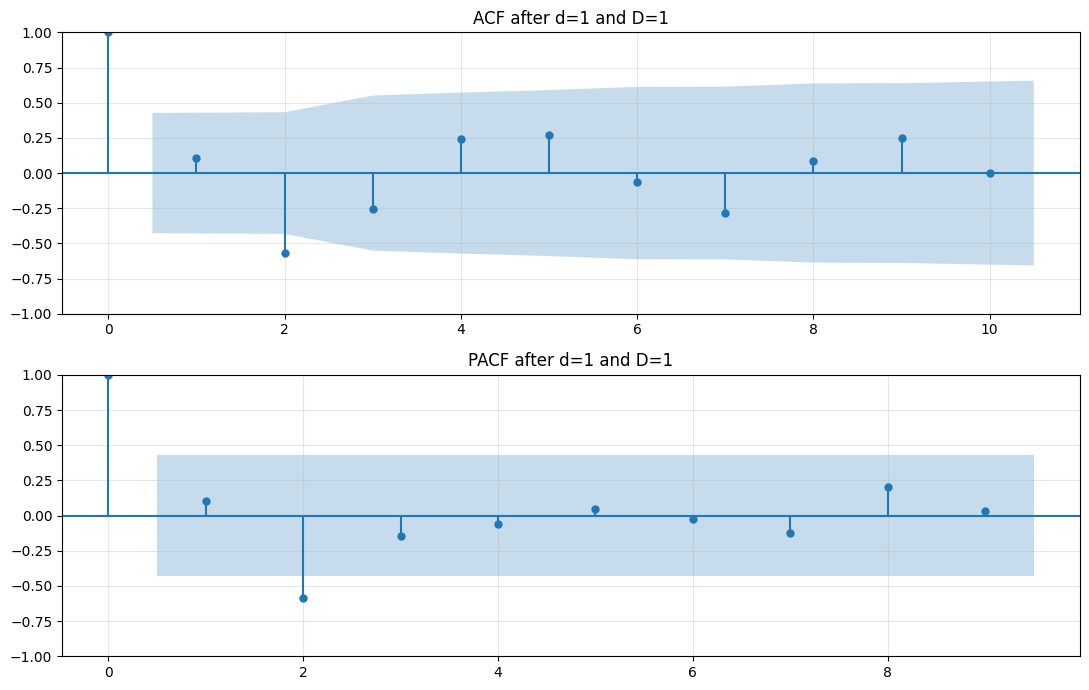

In [33]:
stationary = series_set["Regular + Seasonal (d=1, D=1)"]
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
plot_acf(stationary, lags=10, ax=axes[0], title="ACF after d=1 and D=1")
plot_pacf(stationary, lags=9, method="ywm", ax=axes[1], title="PACF after d=1 and D=1")
plt.tight_layout(); plt.show()

## 4. Train/Test split และ Grid search

- **Train** = 28 เดือนแรก, **Test** = 6 เดือนสุดท้าย (พ.ค. – ต.ค. 2026)
- ทดลอง SARIMA(p,1,q)(P,1,Q)₁₂ ทุกชุด (p,q ≤ 2, P,Q ≤ 1 → 36 โมเดล) แล้วคัดกรอง: converge, Effective N ≥ 12, พารามิเตอร์/SE ต้องเป็นค่าจริง และ AR/MA root อยู่นอกวงกลมหนึ่งหน่วย
- จัดอันดับด้วย RMSE บน Test set
- เทียบ AIC/BIC ได้เฉพาะภายใน Grid นี้ เพราะทุกโมเดลใช้ d=1, D=1 เท่ากัน (Effective N เท่ากัน)

In [34]:
train, test = pm25.iloc[:-N_TEST], pm25.iloc[-N_TEST:]
print(f"Train = {len(train)} ({train.index[0]:%b %Y} – {train.index[-1]:%b %Y})")
print(f"Test  = {len(test)} ({test.index[0]:%b %Y} – {test.index[-1]:%b %Y})")

Train = 28 (Jan 2024 – Apr 2026)
Test  = 6 (May 2026 – Oct 2026)


In [43]:
def grid_search(train, test):
    accepted, rejected = [], []
    space = itertools.product(range(MAX_P + 1), range(MAX_Q + 1), range(MAX_SP + 1), range(MAX_SQ + 1))
    for p, q, P, Q in space:
        order, seasonal = (p, D_ORDER, q), (P, D_SEASONAL, Q, SEASON)
        name = label(order, seasonal)
        try:
            fit = fit_sarima(train, order, seasonal)
            reason = screen(fit)
            if reason:
                rejected.append((name, reason)); continue
            pred = fit.get_forecast(steps=len(test)).predicted_mean
            accepted.append({"Model": name, "p": p, "d": D_ORDER, "q": q, "P": P, "D": D_SEASONAL, "Q": Q,
                             "k": p + q + P + Q, "Effective_N": fit.nobs_effective,
                             "AIC": fit.aic, "BIC": fit.bic, **forecast_metrics(test, pred)})
        except Exception as e:
            rejected.append((name, str(e)[:80]))
    table = pd.DataFrame(accepted).sort_values(["RMSE", "MAE"]).reset_index(drop=True)
    return table, pd.DataFrame(rejected, columns=["Model", "Reason"])

results, rejected = grid_search(train, test)
print(f"ทดสอบ {len(results) + len(rejected)} โมเดล | ผ่านเกณฑ์ {len(results)} | ถูกตัด {len(rejected)}")
display(results[["Model", "Effective_N", "AIC", "BIC", "MAE", "MSE", "RMSE"]].round(4))
if len(rejected):
    print("\nโมเดลที่ถูกตัด:"); display(rejected)

ทดสอบ 36 โมเดล | ผ่านเกณฑ์ 33 | ถูกตัด 3


,Model,Effective_N,AIC,BIC,MAE,MSE,RMSE
0,"SARIMA(0, 1, 2)x(1, 1, 1, 12)",15,101.9109,105.4512,1.2660,3.2989,1.8163
1,"SARIMA(0, 1, 2)x(0, 1, 1, 12)",15,99.9109,102.7431,1.2661,3.2990,1.8163
2,"SARIMA(0, 1, 2)x(1, 1, 0, 12)",15,99.9110,102.7432,1.2660,3.2990,1.8163
3,"SARIMA(1, 1, 2)x(1, 1, 0, 12)",15,100.8458,104.3860,1.5831,3.6369,1.9071
4,"SARIMA(1, 1, 2)x(1, 1, 1, 12)",15,102.8348,107.0831,1.5798,3.6890,1.9207
5,"SARIMA(1, 1, 2)x(0, 1, 1, 12)",15,100.8365,104.3768,1.5877,3.7052,1.9249
6,"SARIMA(1, 1, 2)x(0, 1, 0, 12)",15,100.5281,103.3603,2.0512,5.0028,2.2367
7,"SARIMA(0, 1, 1)x(1, 1, 0, 12)",15,98.1997,100.3239,1.9477,6.3801,2.5259
8,"SARIMA(0, 1, 1)x(0, 1, 1, 12)",15,98.1997,100.3238,1.9477,6.3802,2.5259
9,"SARIMA(0, 1, 1)x(1, 1, 1, 12)",15,100.1997,103.0319,1.9478,6.3807,2.5260



โมเดลที่ถูกตัด:


,Model,Reason
0,"SARIMA(2, 1, 0)x(1, 1, 1, 12)",AR root near boundary
1,"SARIMA(2, 1, 1)x(1, 1, 1, 12)",AR root near boundary
2,"SARIMA(2, 1, 2)x(1, 1, 1, 12)",AR root near boundary


### เลือก Best model

RMSE ของโมเดลอันดับต้น ๆ ต่างกันน้อยมาก (เช่น 1.8163 vs 1.8164) จึงถือว่า **เสมอกัน** แล้วเลือกตัวที่มีพารามิเตอร์น้อยที่สุด (เสมออีก → AIC ต่ำสุด)

In [36]:
tied = results[results["RMSE"] <= results["RMSE"].min() * (1 + RMSE_TOL)]
best = tied.sort_values(["k", "AIC"]).iloc[0]

BEST_ORDER    = (int(best.p), D_ORDER, int(best.q))
BEST_SEASONAL = (int(best.P), D_SEASONAL, int(best.Q), SEASON)
print("โมเดลที่ RMSE เสมอกัน:"); display(tied[["Model", "k", "AIC", "BIC", "RMSE"]].round(4))
print(f"★ Best model = {best.Model}   (RMSE = {best.RMSE:.4f}, AIC = {best.AIC:.2f})")

โมเดลที่ RMSE เสมอกัน:


,Model,k,AIC,BIC,RMSE
0,"SARIMA(0, 1, 2)x(1, 1, 1, 12)",4,101.9109,105.4512,1.8163
1,"SARIMA(0, 1, 2)x(0, 1, 1, 12)",3,99.9109,102.7431,1.8163
2,"SARIMA(0, 1, 2)x(1, 1, 0, 12)",3,99.9110,102.7432,1.8163


★ Best model = SARIMA(0, 1, 2)x(0, 1, 1, 12)   (RMSE = 1.8163, AIC = 99.91)


,Model,MAE,MSE,RMSE
Optimized,"SARIMA(0, 1, 2)x(0, 1, 1, 12)",1.2661,3.299,1.8163


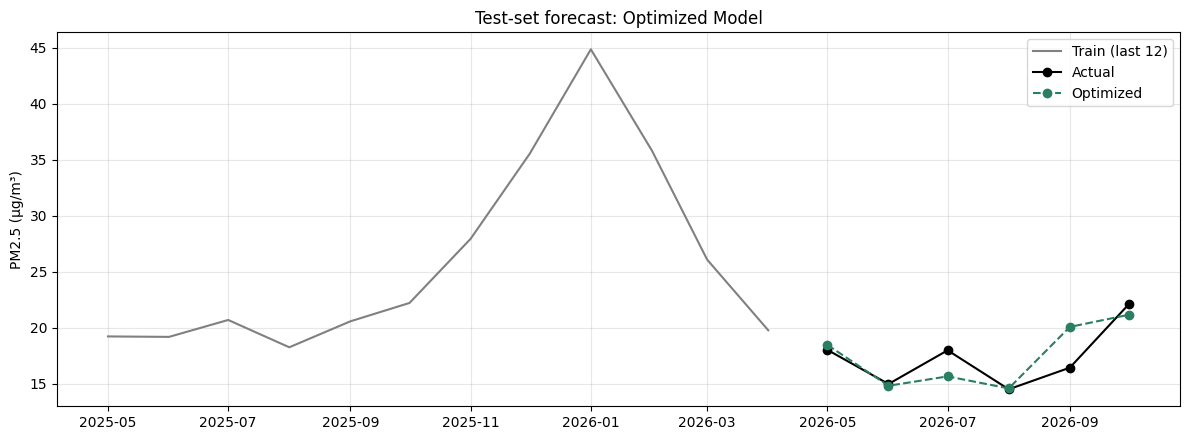

In [37]:
# ประเมิน Optimized Model บน Test set
optimized_fit = fit_sarima(train, BEST_ORDER, BEST_SEASONAL)
optimized_pred = optimized_fit.get_forecast(len(test)).predicted_mean

optimized_metrics = pd.DataFrame([forecast_metrics(test, optimized_pred)], index=["Optimized"])
optimized_metrics.insert(0, "Model", label(BEST_ORDER, BEST_SEASONAL))
display(optimized_metrics.round(4))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(train.index[-12:], train.iloc[-12:], color="gray", label="Train (last 12)")
ax.plot(test.index, test, marker="o", color="k", label="Actual")
ax.plot(
    test.index, optimized_pred,
    marker="o", ls="--", color="#2a7f62", label="Optimized"
)
ax.set(title="Test-set forecast: Optimized Model", ylabel="PM2.5 (µg/m³)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. ตรวจสอบโมเดลที่เลือก

### 5.1 พารามิเตอร์, Residual และ ARCH-LM

In [38]:
fit = optimized_fit
param_table = pd.DataFrame({"Coef": fit.params, "Std Err": fit.bse, "P-value": fit.pvalues})
param_table["CI lower"] = param_table["Coef"] - 1.96 * param_table["Std Err"]
param_table["CI upper"] = param_table["Coef"] + 1.96 * param_table["Std Err"]
param_table["Significant"] = np.where(param_table["P-value"] < ALPHA, "Yes", "No")
print(f"{label(BEST_ORDER, BEST_SEASONAL)}  | Converged = {fit.mle_retvals['converged']} | Effective N = {fit.nobs_effective}")
display(param_table.round(4))

SARIMA(0, 1, 2)x(0, 1, 1, 12)  | Converged = True | Effective N = 15


,Coef,Std Err,P-value,CI lower,CI upper,Significant
ma.L1,1.1275,0.5128,0.0279,0.1224,2.1325,Yes
ma.L2,0.4042,0.6971,0.5620,-0.9622,1.7706,No
ma.S.L12,-0.6201,2.2296,0.7809,-4.9902,3.7500,No
sigma2,18.4717,38.1090,0.6279,-56.2220,93.1653,No


จำนวน Residual ที่ใช้ตรวจ = 15

Ljung-Box (lag 6):


,lb_stat,lb_pvalue
6,4.1937,0.2413


Jarque-Bera = 2.8623, p-value = 0.2390

ARCH-LM (lag 3): LM = 1.5910, p = 0.6614; F = 0.4076, p = 0.7519 → ไม่พบ ARCH effect


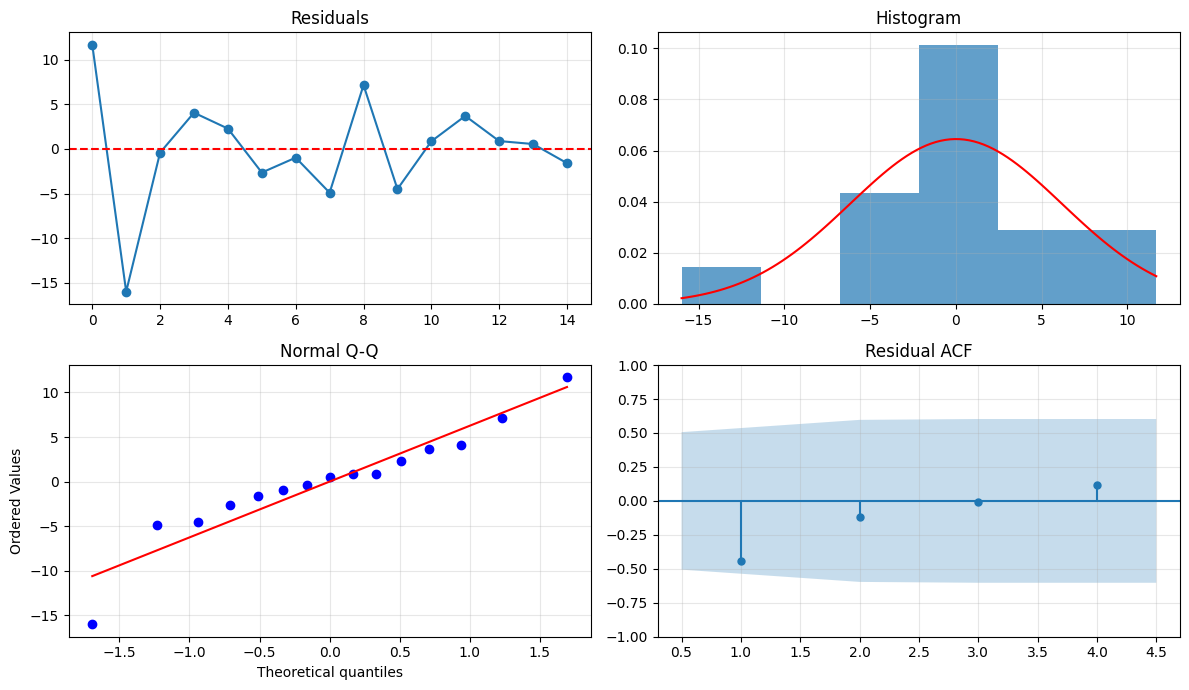

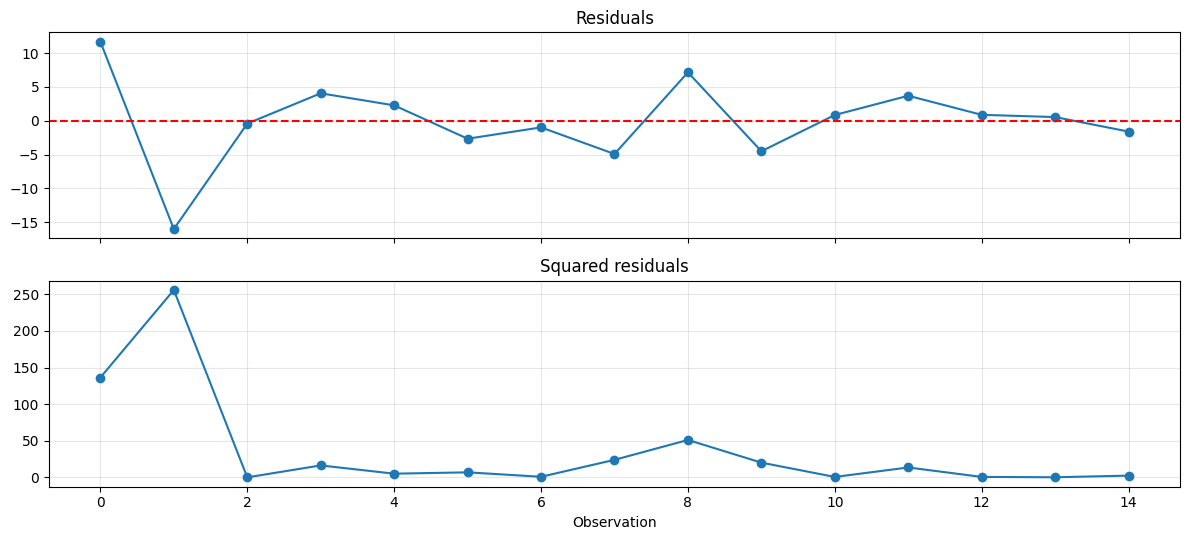

In [39]:
diag = residual_tests(fit, BEST_ORDER, BEST_SEASONAL)
resid = diag["resid"]
print(f"จำนวน Residual ที่ใช้ตรวจ = {len(resid)}")
print("\nLjung-Box (lag 6):"); display(diag["ljung_box"].round(4))
print(f"Jarque-Bera = {diag['jb_stat']:.4f}, p-value = {diag['jb_p']:.4f}")

# ARCH-LM: ความแปรปรวนของ residual ขึ้นกับอดีตหรือไม่ (ใช้ lag 3 เพราะข้อมูลน้อย)
lm, lm_p, f_stat, f_p = het_arch(resid, nlags=3, ddof=0)
print(f"\nARCH-LM (lag 3): LM = {lm:.4f}, p = {lm_p:.4f}; F = {f_stat:.4f}, p = {f_p:.4f} →",
      "พบ ARCH effect" if lm_p < ALPHA else "ไม่พบ ARCH effect")

residual_panel(resid)
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
ax[0].plot(resid.to_numpy(), marker="o"); ax[0].axhline(0, color="red", ls="--"); ax[0].set_title("Residuals")
ax[1].plot(resid.to_numpy() ** 2, marker="o"); ax[1].set(title="Squared residuals", xlabel="Observation")
plt.tight_layout(); plt.show()

In [40]:
# ตำแหน่ง AR/MA roots (ต้องอยู่นอกวงกลมหนึ่งหน่วย → modulus > 1)
for name, roots in [("AR", fit.arroots), ("MA", fit.maroots)]:
    print(f"{name} roots:", np.round(roots, 4) if len(roots) else "ไม่มี",
          "| min modulus =", round(float(np.abs(roots).min()), 4) if len(roots) else "-")

AR roots: ไม่มี | min modulus = -
MA roots: [ 1.0406-0.j      0.9012-0.5203j  0.9012+0.5203j  0.5203-0.9012j
  0.5203+0.9012j -0.    -1.0406j -0.    +1.0406j -0.5203-0.9012j
 -0.5203+0.9012j -1.0406-0.j     -0.9012-0.5203j -0.9012+0.5203j
 -1.3945-0.7274j -1.3945+0.7274j] | min modulus = 1.0406


### 5.2 ความเสถียรของพารามิเตอร์เมื่อเปลี่ยนขนาด Training

ประมาณค่าโมเดลเดิมซ้ำบน training 24, 26, 28 เดือน ถ้าพารามิเตอร์เปลี่ยนมาก (หรือเปลี่ยนเครื่องหมาย) แปลว่าโมเดลยังไม่นิ่งกับข้อมูลปริมาณนี้

In [41]:
rows = []
for n in (24, 26, 28):
    f = fit_sarima(train.iloc[:n], BEST_ORDER, BEST_SEASONAL)
    rows.append({"Train_N": n, "Effective_N": f.nobs_effective,
                 "Converged": f.mle_retvals.get("converged", False), **f.params.to_dict()})
stability = pd.DataFrame(rows)
display(stability.round(4))

,Train_N,Effective_N,Converged,ma.L1,ma.L2,ma.S.L12,sigma2
0,24,11,True,0.1442,-0.6968,0.9938,13.3765
1,26,13,True,0.1821,-0.6003,-0.2792,23.1963
2,28,15,True,1.1275,0.4042,-0.6201,18.4717


## 6. พยากรณ์ 6 เดือนข้างหน้า (พ.ย. 2026 – เม.ย. 2027)

Refit the optimized model on all 34 months to forecast the next 6 months.

Optimized Model: SARIMA(0, 1, 2)x(0, 1, 1, 12)


,Forecast,Lower 95%,Upper 95%
Nov 2026,29.44,22.16,36.72
Dec 2026,37.19,26.18,48.19
Jan 2027,46.61,35.17,58.05
Feb 2027,34.78,22.94,46.62
Mar 2027,23.46,11.23,35.68
Apr 2027,17.50,4.89,30.10


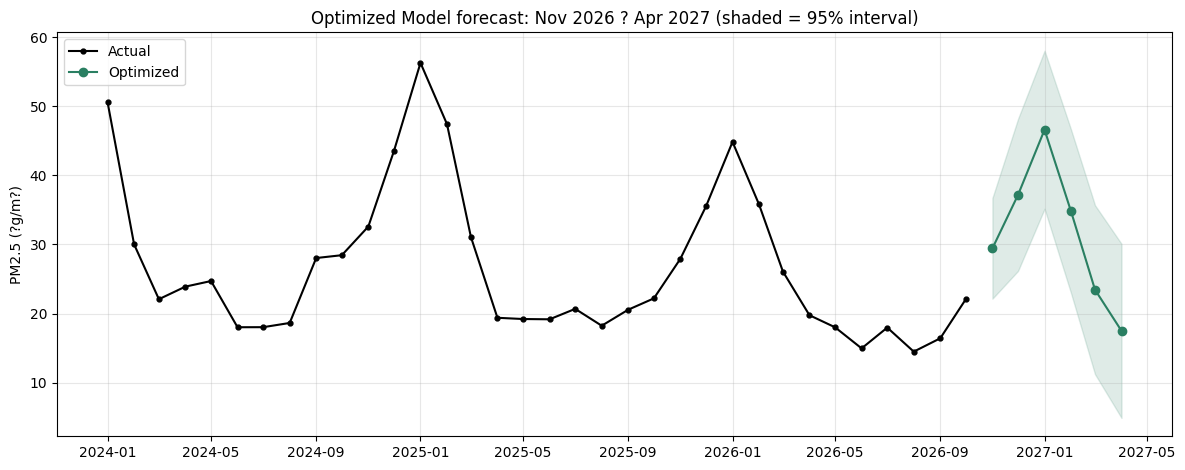

In [42]:
def forecast_table(series, order, seasonal, steps=HORIZON):
    f = fit_sarima(series, order, seasonal).get_forecast(steps)
    ci = f.conf_int(alpha=ALPHA)
    return pd.DataFrame({"Forecast": f.predicted_mean.to_numpy(),
                         "Lower 95%": ci.iloc[:, 0].to_numpy(),
                         "Upper 95%": ci.iloc[:, 1].to_numpy()},
                        index=f.predicted_mean.index)

optimized_forecast = forecast_table(pm25, BEST_ORDER, BEST_SEASONAL)
print(f"Optimized Model: {label(BEST_ORDER, BEST_SEASONAL)}")
display(optimized_forecast.round(2).set_axis(optimized_forecast.index.strftime("%b %Y")))

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(pm25.index, pm25, marker="o", ms=3.5, color="k", label="Actual")
ax.plot(optimized_forecast.index, optimized_forecast["Forecast"], marker="o", color="#2a7f62", label="Optimized")
ax.fill_between(optimized_forecast.index, optimized_forecast["Lower 95%"], optimized_forecast["Upper 95%"], color="#2a7f62", alpha=.15)
ax.set(title="Optimized Model forecast: Nov 2026 ? Apr 2027 (shaded = 95% interval)", ylabel="PM2.5 (?g/m?)")
ax.legend()
plt.tight_layout()
plt.show()